# ATDL Phase 1 — Dataset Audit

This notebook audits the extracted NEU-DET dataset at data/raw/NEU-DET/NEU-DET. It inventories images, parses Pascal VOC XML, checks image/XML matches, records defect counts, and saves reports beneath data/ and results/. The raw dataset is read only.

Run cells from top to bottom using the project .venv kernel.

## 1. Locate the project and the actual dataset root

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import cv2
import json
import xml.etree.ElementTree as ET
from collections import Counter
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "requirements-local.txt").is_file() and (p / "data").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the atdl_final_project folder in VS Code.")

RAW_DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "NEU-DET" / "NEU-DET"
TRAIN_ROOT = RAW_DATA_ROOT / "train"
VAL_ROOT = RAW_DATA_ROOT / "validation"
assert (TRAIN_ROOT / "images").is_dir(), f"Missing {TRAIN_ROOT / 'images'}"
assert (TRAIN_ROOT / "annotations").is_dir(), f"Missing {TRAIN_ROOT / 'annotations'}"
assert (VAL_ROOT / "images").is_dir(), f"Missing {VAL_ROOT / 'images'}"
assert (VAL_ROOT / "annotations").is_dir(), f"Missing {VAL_ROOT / 'annotations'}"

DATA_ROOT = PROJECT_ROOT / "data"
RESULTS_ROOT = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_ROOT / "tables"
FIGURES_DIR = RESULTS_ROOT / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT_ROOT)
print("Correct raw dataset root:", RAW_DATA_ROOT)
print("Train images:", sum(1 for p in (TRAIN_ROOT / "images").rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}))
print("Validation images:", sum(1 for p in (VAL_ROOT / "images").rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}))


Project: .
Correct raw dataset root: ./data/raw/NEU-DET/NEU-DET
Train images: 1440
Validation images: 360


## 2. Inventory images and detect unreadable files

In [2]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_paths = sorted(p for p in RAW_DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
inventory_rows, corrupt_images = [], []

for image_path in image_paths:
    rel = image_path.relative_to(RAW_DATA_ROOT).as_posix()
    try:
        with Image.open(image_path) as image:
            image.verify()
        with Image.open(image_path) as image:
            width, height = image.size
            mode, fmt = image.mode, image.format
            gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
            dct_low = cv2.dct(gray)[:8, :8].flatten()
            phash_median = float(np.median(dct_low[1:]))
            phash_value = sum((1 << bit) for bit, value in enumerate(dct_low) if value > phash_median)
        inventory_rows.append({
            "filename": image_path.name, "relative_path": rel,
            "width": width, "height": height, "mode": mode, "format": fmt,
            "file_size_bytes": image_path.stat().st_size,
            "sha256": hashlib.sha256(image_path.read_bytes()).hexdigest(),
            "perceptual_hash_64": f"{phash_value:016x}",
        })
    except Exception as exc:
        corrupt_images.append({"relative_path": rel, "error": str(exc)})

inventory = pd.DataFrame(inventory_rows)
inventory_path = DATA_ROOT / "image_inventory.csv"
inventory.to_csv(inventory_path, index=False)
display(inventory.head())
print(f"Readable images: {len(inventory_rows)} | unreadable: {len(corrupt_images)}")
exact_duplicate_rows = []
if not inventory.empty:
    duplicate_inventory = inventory[inventory.duplicated("sha256", keep=False)].sort_values(["sha256", "relative_path"])
    for digest, group in duplicate_inventory.groupby("sha256"):
        exact_duplicate_rows.append({
            "sha256": digest, "duplicate_group_id": digest[:16],
            "image_count": len(group), "relative_paths": "|".join(group["relative_path"].tolist()),
        })
exact_duplicate_report = pd.DataFrame(exact_duplicate_rows,
    columns=["sha256", "duplicate_group_id", "image_count", "relative_paths"])
exact_duplicate_report.to_csv(TABLES_DIR / "exact_duplicate_groups.csv", index=False)
display(exact_duplicate_report)
print("Exact duplicate groups:", len(exact_duplicate_report),
      "| images involved:", int(exact_duplicate_report["image_count"].sum()) if not exact_duplicate_report.empty else 0)

PHASH_MAX_DISTANCE = 5
hash_values = [int(value, 16) for value in inventory["perceptual_hash_64"].tolist()]
perceptual_candidates = []
for i in range(len(hash_values)):
    for j in range(i + 1, len(hash_values)):
        distance = (hash_values[i] ^ hash_values[j]).bit_count()
        if distance <= PHASH_MAX_DISTANCE:
            perceptual_candidates.append({
                "hamming_distance": distance,
                "path_a": inventory.iloc[i]["relative_path"],
                "path_b": inventory.iloc[j]["relative_path"],
                "sha256_equal": inventory.iloc[i]["sha256"] == inventory.iloc[j]["sha256"],
            })
perceptual_report = pd.DataFrame(perceptual_candidates,
    columns=["hamming_distance", "path_a", "path_b", "sha256_equal"])
perceptual_report.to_csv(TABLES_DIR / "perceptual_duplicate_candidates.csv", index=False)
print(f"Perceptual-hash candidate pairs (64-bit Hamming <= {PHASH_MAX_DISTANCE}): {len(perceptual_report)}")
if not inventory.empty:
    display(inventory.groupby(["format", "mode"], dropna=False).size().rename("images").reset_index())
    display(inventory[["width", "height"]].describe())


,filename,relative_path,width,height,mode,format,file_size_bytes,sha256,perceptual_hash_64
0,crazing_1.jpg,train/images/crazing/crazing_1.jpg,200,200,RGB,JPEG,22873,5278cd3695adbcbd7a16a7e4b2c6bc27f18095ab8a1e03...,28d2299b3cb3d46b
1,crazing_10.jpg,train/images/crazing/crazing_10.jpg,200,200,RGB,JPEG,21377,522352a6c3532d45a64184b7b1435a74e8cdb732ebdc8e...,3673095c0f377383
2,crazing_100.jpg,train/images/crazing/crazing_100.jpg,200,200,RGB,JPEG,21837,9d0d09aec1914e8bdc876052f357c8d898acfe38d1f9ea...,c2f850799dc3e48b
3,crazing_101.jpg,train/images/crazing/crazing_101.jpg,200,200,RGB,JPEG,22537,0c4ccbfd539aa9d0a151f25b3e798fbad36d2a3532218b...,fc4e0ea5a4c97817
4,crazing_102.jpg,train/images/crazing/crazing_102.jpg,200,200,RGB,JPEG,18818,b4e276eb131f61b44084d0c06640b00cbaecbffb48d3a8...,491cfd194ba130df


Readable images: 1800 | unreadable: 0


,sha256,duplicate_group_id,image_count,relative_paths
0,4d2de82731b86cdbc7a66f2a9bfb01074bb4cb65e47bcc...,4d2de82731b86cdb,2,train/images/patches/patches_101.jpg|train/ima...


Exact duplicate groups: 1 | images involved: 2
Perceptual-hash candidate pairs (64-bit Hamming <= 5): 1


,format,mode,images
0,JPEG,RGB,1800


,width,height
count,1800.0,1800.0
mean,200.0,200.0
std,0.0,0.0
min,200.0,200.0
25%,200.0,200.0
50%,200.0,200.0
75%,200.0,200.0
max,200.0,200.0


## 3. Audit Pascal VOC XML and count objects by class

In [3]:
xml_paths = sorted(RAW_DATA_ROOT.rglob("*.xml"))
xml_rows, xml_errors, object_counts = [], [], Counter()
invalid_boxes = []

for xml_path in xml_paths:
    rel = xml_path.relative_to(RAW_DATA_ROOT).as_posix()
    try:
        root = ET.parse(xml_path).getroot()
        size = root.find("size")
        xml_width = int(size.findtext("width", "0")) if size is not None else 0
        xml_height = int(size.findtext("height", "0")) if size is not None else 0
        names = []
        for obj in root.findall("object"):
            name = (obj.findtext("name") or "").strip().lower().replace(" ", "_")
            names.append(name)
            object_counts[name] += 1
            box = obj.find("bndbox")
            if box is None:
                invalid_boxes.append({"xml": rel, "class": name, "issue": "missing bndbox"})
                continue
            coords = {key: float(box.findtext(key, "nan")) for key in ("xmin", "ymin", "xmax", "ymax")}
            if not all(pd.notna(value) for value in coords.values()):
                invalid_boxes.append({"xml": rel, "class": name, "issue": "non-numeric coordinate"})
            elif xml_width and xml_height and not (
                1 <= coords["xmin"] <= coords["xmax"] <= xml_width
                and 1 <= coords["ymin"] <= coords["ymax"] <= xml_height
            ):
                invalid_boxes.append({"xml": rel, "class": name, "issue": str(coords)})
        xml_rows.append({
            "relative_path": rel, "stem": xml_path.stem, "xml_width": xml_width,
            "xml_height": xml_height, "object_count": len(names),
            "classes_present": ",".join(sorted(set(names))),
        })
    except Exception as exc:
        xml_errors.append({"relative_path": rel, "error": str(exc)})

xml_inventory = pd.DataFrame(xml_rows)
display(xml_inventory.head())
display(pd.DataFrame([{"class_name": k, "object_count": v} for k, v in sorted(object_counts.items())]))
print(f"XML files: {len(xml_paths)} | parsed: {len(xml_rows)} | parse errors: {len(xml_errors)} | invalid boxes: {len(invalid_boxes)}")


,relative_path,stem,xml_width,xml_height,object_count,classes_present
0,train/annotations/crazing_1.xml,crazing_1,200,200,1,crazing
1,train/annotations/crazing_10.xml,crazing_10,200,200,2,crazing
2,train/annotations/crazing_100.xml,crazing_100,200,200,4,crazing
3,train/annotations/crazing_101.xml,crazing_101,200,200,1,crazing
4,train/annotations/crazing_102.xml,crazing_102,200,200,2,crazing


,class_name,object_count
0,crazing,689
1,inclusion,1011
2,patches,881
3,pitted_surface,432
4,rolled-in_scale,628
5,scratches,548


XML files: 1800 | parsed: 1800 | parse errors: 0 | invalid boxes: 0


## 4. Check every image has one matching XML file

In [4]:
images_by_stem, xmls_by_stem = {}, {}
for path in image_paths:
    images_by_stem.setdefault(path.stem, []).append(path)
for path in xml_paths:
    xmls_by_stem.setdefault(path.stem, []).append(path)

ambiguous_image_stems = sorted(stem for stem, paths in images_by_stem.items() if len(paths) != 1)
ambiguous_xml_stems = sorted(stem for stem, paths in xmls_by_stem.items() if len(paths) != 1)
unmatched_images = sorted(stem for stem in images_by_stem if stem not in xmls_by_stem)
unmatched_xmls = sorted(stem for stem in xmls_by_stem if stem not in images_by_stem)
matching_report = {
    "image_count": len(image_paths), "xml_count": len(xml_paths),
    "matched_stem_count": len(set(images_by_stem) & set(xmls_by_stem)),
    "unmatched_images": unmatched_images, "unmatched_xmls": unmatched_xmls,
    "ambiguous_image_stems": ambiguous_image_stems, "ambiguous_xml_stems": ambiguous_xml_stems,
}
display(pd.DataFrame([{"check": key, "count": len(value) if isinstance(value, list) else value}
                      for key, value in matching_report.items()]))


,check,count
0,image_count,1800
1,xml_count,1800
2,matched_stem_count,1800
3,unmatched_images,0
4,unmatched_xmls,0
5,ambiguous_image_stems,0
6,ambiguous_xml_stems,0


## 5. Save audit reports and a class-distribution figure

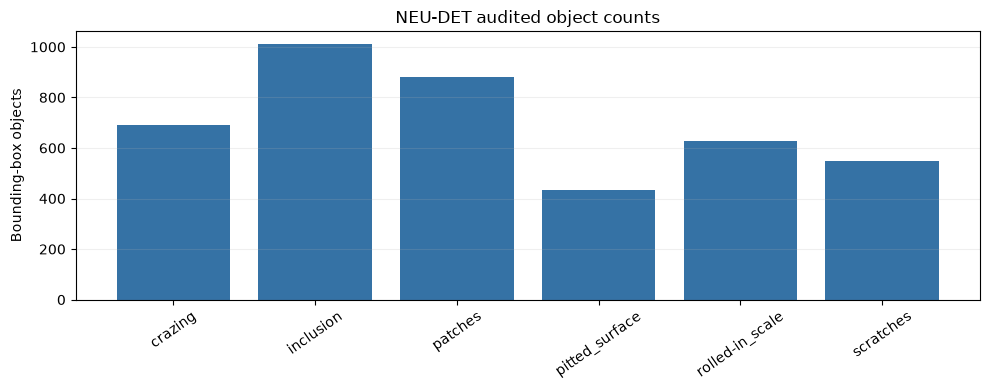

Saved inventory: ./data/image_inventory.csv
Saved Phase 1 audit: ./results/tables/phase1_dataset_audit.json


In [5]:
class_names = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
class_object_counts = {name: int(object_counts.get(name, 0)) for name in class_names}
class_df = pd.DataFrame([{"defect_class": name, "object_count": count}
                         for name, count in class_object_counts.items()])
total_objects = int(class_df["object_count"].sum())
class_df["percentage"] = 100 * class_df["object_count"] / max(total_objects, 1)
class_df.to_csv(TABLES_DIR / "class_object_distribution.csv", index=False)

pd.DataFrame(corrupt_images).to_json(TABLES_DIR / "corrupted_images.json", orient="records", indent=2)
xml_report = {
    "total_xml_files": len(xml_paths), "successfully_parsed_xml": len(xml_rows),
    "total_annotated_objects": total_objects, "class_counts": class_object_counts,
    "parse_errors": xml_errors, "invalid_annotations": invalid_boxes,
}
(TABLES_DIR / "xml_annotation_audit.json").write_text(json.dumps(xml_report, indent=2) + "\n", encoding="utf-8")
(TABLES_DIR / "image_xml_matching.json").write_text(json.dumps(matching_report, indent=2) + "\n", encoding="utf-8")

archive = PROJECT_ROOT / "dataset" / "dataset.zip"
audit = {
    "project_name": "ATDL Final Project", "dataset_name": "NEU-DET",
    "dataset_source": "Northeastern University NEU surface defect database; source URL documented in README.md",
    "raw_dataset_directory": str(RAW_DATA_ROOT),
    "dataset_zip": str(archive),
    "dataset_sha256": hashlib.sha256(archive.read_bytes()).hexdigest() if archive.is_file() else None,
    "image_statistics": {
        "total_valid_images": len(inventory_rows), "corrupted_images": len(corrupt_images),
        "image_formats": inventory["format"].value_counts().to_dict() if not inventory.empty else {},
        "image_modes": inventory["mode"].value_counts().to_dict() if not inventory.empty else {},
        "exact_duplicate_groups": int(len(exact_duplicate_report)),
        "images_in_exact_duplicate_groups": int(exact_duplicate_report["image_count"].sum()) if not exact_duplicate_report.empty else 0,
    },
    "annotation_statistics": xml_report,
    "matching_statistics": matching_report,
    "class_distribution": class_object_counts,
}
(TABLES_DIR / "phase1_dataset_audit.json").write_text(json.dumps(audit, indent=2) + "\n", encoding="utf-8")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_df["defect_class"], class_df["object_count"], color="#3572A5")
ax.set_ylabel("Bounding-box objects")
ax.set_title("NEU-DET audited object counts")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_distribution.png", dpi=160)
plt.show()

print("Saved inventory:", inventory_path)
print("Saved Phase 1 audit:", TABLES_DIR / "phase1_dataset_audit.json")


## Phase 1 completion

Reports derive from the files under the corrected raw dataset root. Review annotation previews before relying on the coordinate convention in Phase 2.